# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


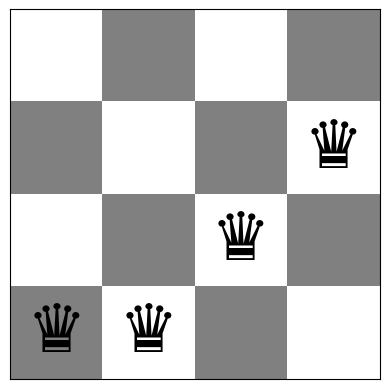

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


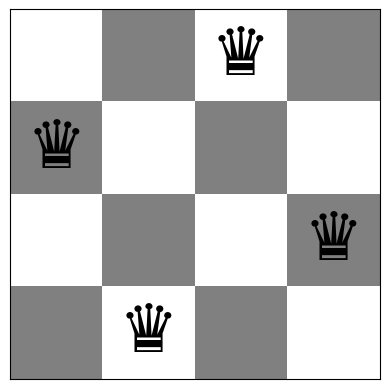

In [4]:
board = [1,3,0,2]
show_board(board)

---
# Bài 2 (Lab 03). Mô hình hóa bài toán n quân hậu

**Phạm vi:** Khảo sát các hàm `random_board(n)`, `show_board(board)`, `conflicts(board)` trong notebook gốc; mô hình hóa trạng thái, sinh lân cận và đối chiếu bài toán 4-Queens, 8-Queens. Phần này bổ sung cho các ví dụ ở trên, **không triển khai sẵn các Task 1–6** của những bài thực hành sau.

## 2.1. Mục tiêu và biểu diễn trạng thái

Bài toán n-Queens yêu cầu đặt `n` quân hậu trên bàn cờ `n × n` để không có hai quân hậu nào tấn công nhau. Mỗi trạng thái được biểu diễn bởi vector `board = [q_0, q_1, ..., q_(n-1)]`, trong đó `q_j` là chỉ số hàng của quân hậu ở cột `j` (đánh số từ 0). Mỗi cột luôn có **đúng một quân hậu** nhưng có thể có nhiều quân cùng hàng hoặc đường chéo, do đó vẫn có xung đột.

- Không gian trạng thái có `n^n` cấu hình: `4^4 = 256` khi n = 4 và `8^8 = 16.777.216` khi n = 8.
- Trạng thái đích: mọi cặp hậu không cùng hàng và không cùng đường chéo.
- Phép dịch chuyển cục bộ: chọn một cột rồi chuyển quân hậu ở cột đó đến **một hàng khác** trong cùng cột.
- Mỗi trạng thái có đúng `n × (n − 1)` láng giềng phân biệt: `12` với n = 4 và `56` với n = 8.

## 2.2. Hàm mục tiêu `conflicts(board)`

Cần cực tiểu hóa `f(board) = conflicts(board)` đến giá trị `0`. Hàm đếm tổng số **cặp** quân hậu tấn công nhau; một cặp có xung đột khi cùng hàng hoặc một trong hai đường chéo. Vì mỗi cột đã có sẵn đúng một quân, không cần xét xung đột cùng cột.

Notebook gốc đếm số quân hậu trên mỗi hàng và hai loại đường chéo, sau đó cộng `C(k, 2) = k(k−1)/2` cho từng hàng/đường chéo chứa `k` quân. Ví dụ, 3 quân cùng hàng tạo ra `C(3, 2) = 3` cặp xung đột; không phải chỉ 1 xung đột.

Ở các phần dưới, hàm `conflicts(board)` và `show_board(board)` **đều được dùng lại nguyên bản** từ cell của giảng viên.

In [5]:
# Bài 2 — Sinh trạng thái ngẫu nhiên có khả năng tái lập.
# random_board() sử dụng bộ sinh số ngẫu nhiên NumPy toàn cục trong notebook gốc.
EX2_SEED = 20261015
np.random.seed(EX2_SEED)

board_4_random = random_board(4)
board_8_random = random_board(8)
board_4_solution = np.asarray([1, 3, 0, 2], dtype=int)

for name, board in [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]:
    n = len(board)
    assert len(board) == n and all(0 <= int(x) < n for x in board)
    print(f'{name:22s} | board={board.tolist()} | n={n} | f={conflicts(board)}')

assert conflicts(board_4_solution) == 0
print(f'Random seed: {EX2_SEED}')

4-Queens ngẫu nhiên    | board=[3, 0, 3, 1] | n=4 | f=1
4-Queens tham chiếu    | board=[1, 3, 0, 2] | n=4 | f=0
8-Queens ngẫu nhiên    | board=[6, 3, 2, 3, 1, 0, 5, 2] | n=8 | f=7
Random seed: 20261015


### Khảo sát ba hàm có sẵn

- `random_board(n)` sinh mảng NumPy gồm `n` chỉ số hàng, mỗi chỉ số thuộc `[0, n−1]`; một quân hậu được đặt trên mỗi cột.
- `show_board(board)` trực quan hóa bàn cờ và in số cặp xung đột bằng `conflicts(board)`; hàm này **không** tự tối ưu cấu hình.
- `conflicts(board)` trả về số cặp hậu xung đột. Giá trị `0` là điều kiện nghiệm hợp lệ, còn giá trị lớn hơn `0` biểu thị còn ít nhất một cặp xung đột.

Các hình sau cho thấy hai bàn cờ ngẫu nhiên và một lời giải 4-Queens đã biết. Hình vẽ nhằm **khảo sát mô hình trạng thái**, không phải kết quả của thuật toán Hill Climbing.


Bàn cờ 4×4 ngẫu nhiên: [3, 0, 3, 1]
Board with 1 conflicts.


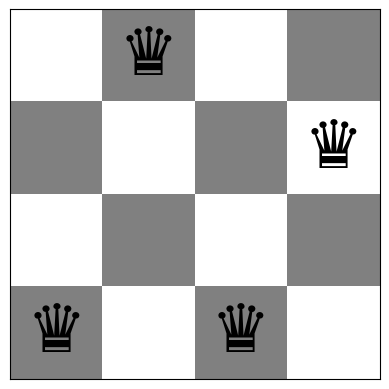


Bàn cờ 4×4 không xung đột [1,3,0,2]: [1, 3, 0, 2]
Board with 0 conflicts.


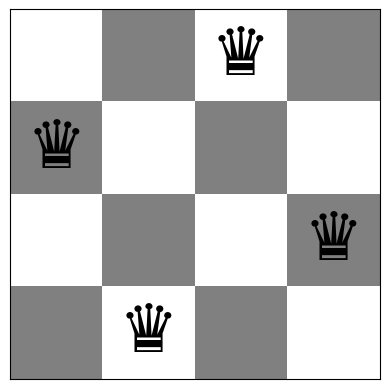


Bàn cờ 8×8 ngẫu nhiên: [6, 3, 2, 3, 1, 0, 5, 2]
Board with 7 conflicts.


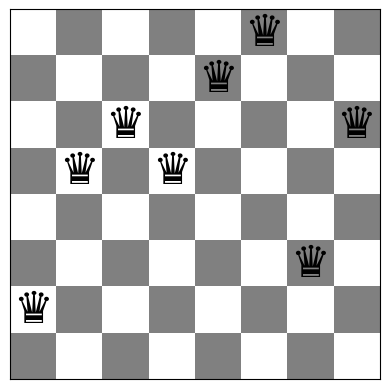

In [6]:
# Trực quan hóa bằng show_board() đã có trong notebook gốc.
for title, board, fs in [
    ('Bàn cờ 4×4 ngẫu nhiên', board_4_random, 48),
    ('Bàn cờ 4×4 không xung đột [1,3,0,2]', board_4_solution, 48),
    ('Bàn cờ 8×8 ngẫu nhiên', board_8_random, 32),
]:
    print(f'\n{title}: {board.tolist()}')
    show_board(board, fontsize=fs)

## 2.3. Trạng thái lân cận và phép di chuyển cục bộ

Với một bàn cờ có `n` cột, mỗi cột có `n−1` lựa chọn hàng mới, nên số lân cận là `n(n−1)`. Để sinh các lân cận, chương trình sao chép vector trạng thái hiện tại, chỉ thay đổi đúng một phần tử `board[column]` sang hàng mới, sau đó giữ các phần tử còn lại. Việc tạo bản sao bảo đảm **không làm biến đổi bàn cờ gốc** trong khi đánh giá các lựa chọn.

Hàm `local_neighbors(board)` dưới đây chỉ dùng để *mô hình hóa và kiểm chứng không gian lân cận*. Nó không chọn bước tốt hơn, nên chưa phải thuật toán Hill Climbing.

In [7]:
def local_neighbors(board):
    """Trả về (cột được chọn, hàng mới, bàn cờ mới) cho mọi bước hợp lệ."""
    current = np.asarray(board, dtype=int)
    n = len(current)
    neighbors = []
    for column in range(n):
        for new_row in range(n):
            if new_row == current[column]:
                continue  # Không tính thao tác đứng yên là một lân cận.
            moved = current.copy()
            moved[column] = new_row
            neighbors.append((column, new_row, moved))
    return neighbors

for name, board in [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]:
    n = len(board)
    neighbors = local_neighbors(board)
    unique_boards = {tuple(x[2]) for x in neighbors}
    assert len(neighbors) == len(unique_boards) == n * (n - 1)
    assert all(np.count_nonzero(new_board != board) == 1
               for _, _, new_board in neighbors)
    print(f'{name:22s}: {len(neighbors)} láng giềng; '
          f'công thức n(n-1) = {n}×{n-1} = {n * (n - 1)}')

print('Ví dụ 5 lân cận đầu tiên của board 4-Queens ngẫu nhiên:')
for col, row, new_board in local_neighbors(board_4_random)[:5]:
    print(f'  cột={col}, hàng mới={row}: {new_board.tolist()}, '
          f'f={conflicts(new_board)}')

4-Queens ngẫu nhiên   : 12 láng giềng; công thức n(n-1) = 4×3 = 12
4-Queens tham chiếu   : 12 láng giềng; công thức n(n-1) = 4×3 = 12
8-Queens ngẫu nhiên   : 56 láng giềng; công thức n(n-1) = 8×7 = 56
Ví dụ 5 lân cận đầu tiên của board 4-Queens ngẫu nhiên:
  cột=0, hàng mới=0: [0, 0, 3, 1], f=1
  cột=0, hàng mới=1: [1, 0, 3, 1], f=3
  cột=0, hàng mới=2: [2, 0, 3, 1], f=0
  cột=1, hàng mới=1: [3, 1, 3, 1], f=2
  cột=1, hàng mới=2: [3, 2, 3, 1], f=3


## 2.4. Thực nghiệm n = 4 và n = 8

Ở đây ta so sánh: (1) bàn cờ 4-Queens ngẫu nhiên, (2) cấu hình tham chiếu `[1,3,0,2]`, (3) bàn cờ 8-Queens ngẫu nhiên. Ngoài giá trị `f(board)`, mã còn thống kê phân bố giá trị xung đột trong **toàn bộ lân cận một bước**. Bảng này giúp chuẩn bị cho việc chọn bước cải thiện trong các Task 1–3 về Hill Climbing.

Các phép đo sử dụng một seed cố định; kết quả cụ thể của bàn cờ ngẫu nhiên có thể khác nếu bạn đổi seed hoặc phiên bản trình tạo số ngẫu nhiên.

In [8]:
# Kiểm chứng độc lập cách đếm số cặp hậu tấn công nhau.
def conflicts_pairwise(board):
    board = np.asarray(board, dtype=int)
    n = len(board)
    return sum(
        board[i] == board[j] or abs(int(board[i]) - int(board[j])) == j - i
        for i in range(n) for j in range(i + 1, n)
    )

boards_to_compare = [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]
results_bai2 = []
for name, board in boards_to_compare:
    n = len(board)
    neighbor_conflicts = [conflicts(new_board)
                          for _, _, new_board in local_neighbors(board)]
    current_f = conflicts(board)
    assert current_f == conflicts_pairwise(board)
    result = {
        'case': name, 'n': n, 'state': str(board.tolist()),
        'conflicts': current_f,
        'n_neighbors': len(neighbor_conflicts),
        'min_neighbor_conflicts': min(neighbor_conflicts),
        'improving_neighbors': sum(v < current_f for v in neighbor_conflicts),
        'zero_conflict_neighbors': sum(v == 0 for v in neighbor_conflicts),
    }
    results_bai2.append(result)

print(f'{"Thí nghiệm":23s} {"n":>2s} {"f":>4s} {"Láng giềng":>11s} '
      f'{"f nhỏ nhất":>12s} {"Cải thiện":>10s} {"f=0":>6s}')
for row in results_bai2:
    print(f'{row["case"]:23s} {row["n"]:2d} {row["conflicts"]:4d} '
          f'{row["n_neighbors"]:11d} {row["min_neighbor_conflicts"]:12d} '
          f'{row["improving_neighbors"]:10d} {row["zero_conflict_neighbors"]:6d}')

assert conflicts(board_4_solution) == 0
assert len(local_neighbors(board_4_random)) == 12
assert len(local_neighbors(board_8_random)) == 56
print('Kiểm thử: PASS (xung đột, kích thước lân cận, lời giải mẫu).')

Thí nghiệm               n    f  Láng giềng   f nhỏ nhất  Cải thiện    f=0
4-Queens ngẫu nhiên      4    1          12            0          1      1
4-Queens tham chiếu      4    0          12            1          0      0
8-Queens ngẫu nhiên      8    7          56            4         17      0
Kiểm thử: PASS (xung đột, kích thước lân cận, lời giải mẫu).


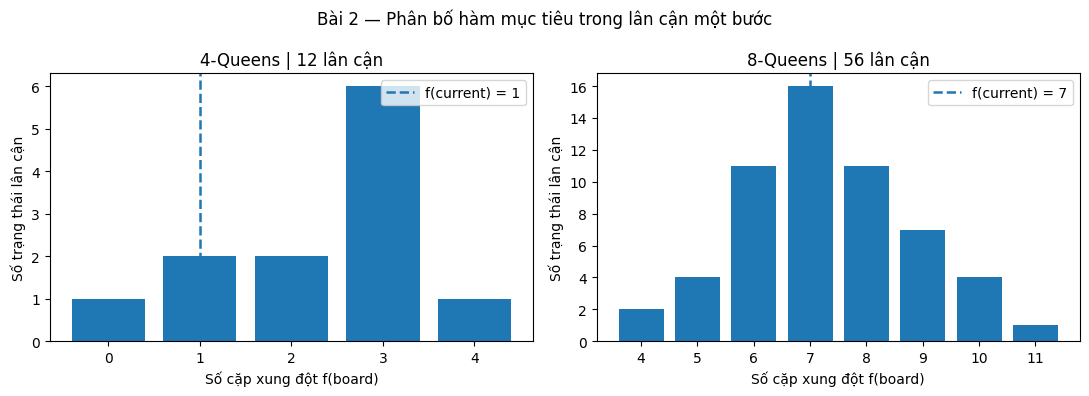

In [9]:
# Vẽ phân bố số xung đột ở các lân cận của 4-Queens và 8-Queens.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, n, board in zip(axes, [4, 8], [board_4_random, board_8_random]):
    vals = [conflicts(state) for _, _, state in local_neighbors(board)]
    xvalues = np.arange(min(vals), max(vals) + 1)
    counts = [vals.count(int(k)) for k in xvalues]
    ax.bar(xvalues, counts)
    ax.axvline(conflicts(board), linestyle='--', linewidth=1.8,
               label=f'f(current) = {conflicts(board)}')
    ax.set_title(f'{n}-Queens | {len(vals)} lân cận')
    ax.set_xlabel('Số cặp xung đột f(board)')
    ax.set_ylabel('Số trạng thái lân cận')
    ax.set_xticks(xvalues)
    ax.legend()
fig.suptitle('Bài 2 — Phân bố hàm mục tiêu trong lân cận một bước')
fig.tight_layout()
plt.show()

## 2.5. Nhận xét và kết luận

Với seed **20261015**, `random_board(4)` tạo `[3,0,3,1]` có `f=1`, còn cấu hình tham chiếu `[1,3,0,2]` có `f=0`, do không có hai quân hậu nào cùng hàng hoặc đường chéo. `random_board(8)` tạo `[6,3,2,3,1,0,5,2]` với `f=7`. Giá trị `f` trong các ví dụ này đã được đối chiếu bằng một phép đếm cặp quân hậu độc lập.

- Khi **n=4**, mỗi bàn cờ có `4×3=12` lân cận. Bàn cờ ngẫu nhiên có 1 lân cận cải thiện được `f` xuống 0. Tại `[1,3,0,2]`, mọi phép chuyển một quân hậu sang hàng khác đều làm phát sinh xung đột, vì vậy không có lân cận nào cải thiện so với `f=0`.
- Khi **n=8**, số lân cận tăng thành `8×7=56`. Trong thí nghiệm này, bàn cờ ngẫu nhiên có 17 lân cận giảm `f` so với trạng thái hiện tại, nhưng không có lân cận nào đạt ngay `f=0`.

Biểu diễn một quân hậu trên mỗi cột loại bỏ hoàn toàn các xung đột theo cột và làm trạng thái gọn hơn so với việc xét mọi cách chọn `n` ô bất kỳ trên bàn cờ. Hàm `conflicts(board)` định lượng chất lượng trạng thái, còn toán tử chuyển một quân hậu sang hàng khác xác định cấu trúc lân cận cho các thuật toán tìm kiếm cục bộ ở những bài tiếp theo.

**Giới hạn phạm vi:** Bài 2 chỉ mô hình hóa, sinh lân cận và đánh giá hàm mục tiêu. Nó không chứng minh rằng Hill Climbing hoặc phương pháp nào khác chắc chắn tìm được nghiệm; những thuật toán đó sẽ được triển khai ở Bài 3 và Bài 4.

### Các kết quả cần nhớ

| Nội dung | n = 4 | n = 8 |
|---|---:|---:|
| Số trạng thái theo biểu diễn vector | 256 | 16.777.216 |
| Số lân cận một bước | 12 | 56 |
| Mục tiêu | `f(board)=0` | `f(board)=0` |

Toàn bộ các Task 1–6 trong notebook gốc được giữ nguyên để tiếp tục ở các bài thực hành sau.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [10]:
# Code and description go here

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [11]:
# Code and description go here

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [12]:
# Code and description go here

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [13]:
# Code and description go here

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [14]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [15]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [16]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [17]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [18]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [19]:
# Code and description go here